# Pipeline Preprocessing Ulasan E-Commerce Berbahasa Indonesia
## Eksplorasi Data, Normalisasi Teks, dan Evaluasi Kualitas

**Nama:** Oji Ferdian  
**NIM:** 24146110  
**Mata Kuliah:** Natural Language Processing  
**Dataset:** [dipawidia/ecommerce-product-reviews-sentiment](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment)

Notebook ini menyusun proses preprocessing dari tahap audit data sampai evaluasi kualitas. Fokusnya bukan hanya membersihkan teks, tetapi juga mengukur tahap mana yang paling berpengaruh dan informasi apa yang berpotensi hilang.

## 0. Pertanyaan Analisis dan Alur Kerja

Notebook ini menjawab tiga pertanyaan:

1. Seperti apa karakteristik awal dataset, termasuk keseimbangan label dan panjang ulasan?
2. Tahap preprocessing mana yang paling besar pengaruhnya terhadap panjang teks dan ukuran kosakata?
3. Informasi apa yang berpotensi hilang akibat preprocessing, khususnya pada ulasan yang menjadi kosong atau terlalu pendek?

Alur yang dipakai: **audit dataset -> eksplorasi label dan panjang -> rancangan normalisasi -> perbandingan konfigurasi -> audit kualitas -> contoh sebelum/sesudah -> evaluasi dampak -> diskusi**.

File `labeledReview.datasetFix.json` tidak diubah. Kolom `translate` hanya ditampilkan sebagai informasi dan tidak dipakai dalam analisis.

In [1]:
import html
import json
import re
import time
from collections import Counter
from importlib.metadata import version as pkg_version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

%matplotlib inline

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

WARNA = {
    "negatif": "#B23A48",
    "positif": "#2A6F5E",
    "netral": "#7A7A7A",
    "aksen": "#D99A2B",
    "gelap": "#1F2D3D",
}
URUTAN_LABEL = ["Negatif", "Positif"]
PALET = {"Negatif": WARNA["negatif"], "Positif": WARNA["positif"]}

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D9D9D9",
    "axes.grid": True,
    "grid.color": "#EDEDED",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

DATA_PATH = "labeledReview.datasetFix.json"

print("Versi pustaka:")
for nama in ["pandas", "numpy", "matplotlib", "seaborn", "PySastrawi"]:
    try:
        print(f"  {nama:<12}: {pkg_version(nama)}")
    except Exception:
        print(f"  {nama:<12}: tidak terdeteksi")

Versi pustaka:
  pandas      : 3.0.4
  numpy       : 2.5.0
  matplotlib  : 3.11.1
  seaborn     : 0.13.2
  PySastrawi  : 1.2.1


## 1. Audit Dataset

Sebelum teks dibersihkan, saya periksa jumlah baris, tipe data, nilai kosong, duplikasi, dan ukuran awal teks. Tahap ini penting supaya keputusan preprocessing tidak diambil berdasarkan asumsi.

In [2]:
with open(DATA_PATH, encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
kolom_asli = list(df.columns)
df["sentimen_label"] = df["sentimen"].map({0: "Negatif", 1: "Positif"})
df["jumlah_karakter_awal"] = df["review"].str.len()
df["jumlah_kata_awal"] = df["review"].apply(
    lambda teks: len(re.sub(r"[^a-z\s]", " ", str(teks).lower()).split())
)

vocab_awal_kasar = set()
for teks in df["review"].astype(str).str.lower():
    vocab_awal_kasar.update(re.sub(r"[^a-z\s]", " ", teks).split())

duplikat_review = int(df.duplicated(subset="review").sum())

audit = pd.DataFrame({
    "Metrik": [
        "Jumlah ulasan",
        "Jumlah kolom asli",
        "Kolom",
        "Ulasan duplikat (teks identik)",
        "Nilai kosong",
        "Rata-rata karakter",
        "Median karakter",
        "Rata-rata kata",
        "Median kata",
        "Kata terbanyak",
        "Kosakata unik awal",
    ],
    "Nilai": [
        f"{len(df):,}",
        f"{len(kolom_asli)}",
        ", ".join(kolom_asli),
        f"{duplikat_review:,}",
        f"{int(df[kolom_asli].isna().sum().sum()):,}",
        f"{df['jumlah_karakter_awal'].mean():,.2f}",
        f"{df['jumlah_karakter_awal'].median():,.0f}",
        f"{df['jumlah_kata_awal'].mean():,.2f}",
        f"{df['jumlah_kata_awal'].median():,.0f}",
        f"{df['jumlah_kata_awal'].max():,}",
        f"{len(vocab_awal_kasar):,}",
    ],
})
display(audit)

print("Contoh tiga ulasan pertama:")
display(df[["review", "sentimen"]].head(3))

,Metrik,Nilai
0,Jumlah ulasan,"11,606"
1,Jumlah kolom asli,3
2,Kolom,"review, sentimen, translate"
3,Ulasan duplikat (teks identik),7
4,Nilai kosong,0
5,Rata-rata karakter,103.57
6,Median karakter,78
7,Rata-rata kata,15.74
8,Median kata,12
9,Kata terbanyak,234


Contoh tiga ulasan pertama:


,review,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,0
1,Good. Mudah-mudahan awet. Makasih,1
2,"kondisi dus robek2, tolong di perhatikan lagi",0


### 1.1 Komposisi Label

Saya cek keseimbangan label karena distribusi yang timpang dapat membuat evaluasi model berikutnya bias. Grafik dibuat horizontal agar persentase mudah dibaca.

,Sentimen,Jumlah,Persentase (%)
0,Negatif,5803,50.0
1,Positif,5803,50.0


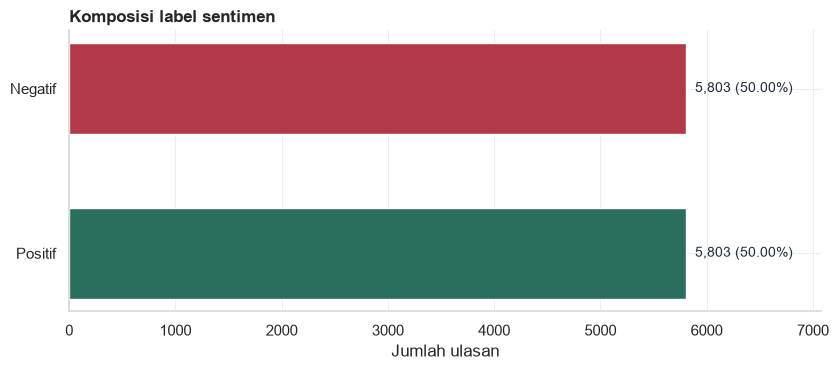

In [3]:
jumlah_label = df["sentimen_label"].value_counts().reindex(URUTAN_LABEL)
persen_label = (jumlah_label / len(df) * 100).round(2)

tabel_label = pd.DataFrame({
    "Sentimen": URUTAN_LABEL,
    "Jumlah": jumlah_label.values,
    "Persentase (%)": persen_label.values,
})
display(tabel_label)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
batang = ax.barh(
    tabel_label["Sentimen"],
    tabel_label["Jumlah"],
    color=[PALET[x] for x in URUTAN_LABEL],
    height=0.55,
)
for bar, jml, pct in zip(batang, tabel_label["Jumlah"], tabel_label["Persentase (%)"]):
    ax.text(
        bar.get_width() + jumlah_label.max() * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{jml:,} ({pct:.2f}%)",
        va="center",
        fontsize=10,
        color=WARNA["gelap"],
    )
ax.set_xlim(0, jumlah_label.max() * 1.22)
ax.set_xlabel("Jumlah ulasan")
ax.set_ylabel("")
ax.set_title("Komposisi label sentimen", loc="left", fontweight="bold")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 1.2 Sebaran Panjang Ulasan

Panjang ulasan memengaruhi seberapa banyak konteks yang tersedia untuk analisis sentimen. Saya bandingkan distribusinya per label, lalu memakai batas persentil ke-99 agar ekor distribusi tidak menutupi pola utama.

,Jumlah,Rata-rata,Median,Maksimum
sentimen_label,,,,
Negatif,5803,19.18,14.0,234
Positif,5803,12.30,10.0,112


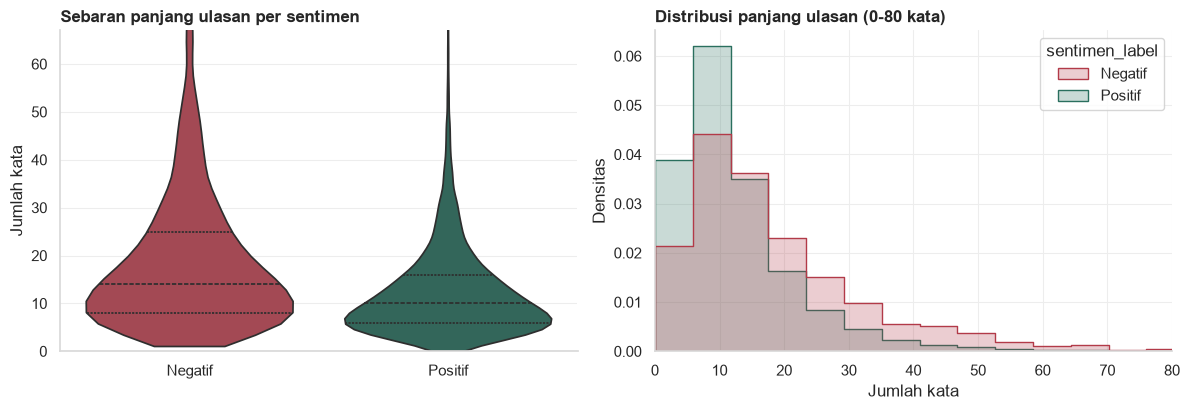

In [4]:
statistik_panjang = (
    df.groupby("sentimen_label")["jumlah_kata_awal"]
      .agg(Jumlah="size", Rata_rata="mean", Median="median", Maksimum="max")
      .reindex(URUTAN_LABEL)
      .rename(columns={"Rata_rata": "Rata-rata"})
      .round(2)
)
display(statistik_panjang)

batas_atas = df["jumlah_kata_awal"].quantile(0.99)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))

sns.violinplot(
    data=df,
    x="sentimen_label",
    y="jumlah_kata_awal",
    hue="sentimen_label",
    order=URUTAN_LABEL,
    hue_order=URUTAN_LABEL,
    palette=PALET,
    inner="quartile",
    cut=0,
    legend=False,
    ax=ax[0],
)
ax[0].set_ylim(0, batas_atas)
ax[0].set_xlabel("")
ax[0].set_ylabel("Jumlah kata")
ax[0].set_title("Sebaran panjang ulasan per sentimen", loc="left", fontweight="bold")

sns.histplot(
    data=df,
    x="jumlah_kata_awal",
    hue="sentimen_label",
    hue_order=URUTAN_LABEL,
    palette=PALET,
    bins=40,
    element="step",
    common_norm=False,
    stat="density",
    ax=ax[1],
)
ax[1].set_xlim(0, 80)
ax[1].set_xlabel("Jumlah kata")
ax[1].set_ylabel("Densitas")
ax[1].set_title("Distribusi panjang ulasan (0-80 kata)", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Merancang Pipeline Preprocessing

Pipeline disusun dari lima tahap utama:

1. **Case folding** - mengubah seluruh huruf menjadi kecil.
2. **Normalisasi dan cleaning** - menyeragamkan singkatan dan pengulangan huruf, lalu menghapus URL, mention, angka, tanda baca, dan emoji.
3. **Tokenisasi** - memecah teks menjadi token kata.
4. **Stopword removal** - menghapus kata umum dengan tetap mempertahankan kata yang membawa makna sentimen.
5. **Stemming** - mengubah kata berimbuhan menjadi bentuk dasar dengan Sastrawi.

Salah satu keputusan penting ada pada tahap 4. Daftar stopword Sastrawi memuat kata negasi dan penguat makna. Jika semua kata itu dihapus, kalimat seperti "tidak bagus" bisa kehilangan pembalik maknanya. Karena itu saya mempertahankan tiga kelompok kata: negasi, intensifier, dan konjungsi kontras.

In [5]:
STOPWORD_SASTRAWI = set(StopWordRemoverFactory().get_stop_words())

NEGASI = {
    "tidak", "bukan", "jangan", "belum", "kurang", "tanpa", "tak",
    "gak", "ga", "nggak", "tdk", "enggak", "gk", "blm",
}
INTENSIFIER = {"sangat", "banget", "sekali", "amat", "paling", "terlalu", "begitu", "cukup"}
KONTRAS = {"tapi", "tetapi", "namun", "sayangnya", "meski", "meskipun", "walau", "walaupun"}

KATA_PENTING = NEGASI | INTENSIFIER | KONTRAS
STOPWORD = STOPWORD_SASTRAWI - KATA_PENTING

tabel_stopword = pd.DataFrame([
    {
        "Kategori": nama,
        "Jumlah": len(kumpulan),
        "Ada di Sastrawi": len(kumpulan & STOPWORD_SASTRAWI),
        "Contoh": ", ".join(sorted(kumpulan)[:6]),
    }
    for nama, kumpulan in [
        ("Negasi", NEGASI),
        ("Intensifier", INTENSIFIER),
        ("Kontras", KONTRAS),
    ]
])
display(tabel_stopword)
print(f"Stopword Sastrawi          : {len(STOPWORD_SASTRAWI):,}")
print(f"Kata penting dipertahankan : {len(KATA_PENTING)}")
print(f"Stopword yang dipakai      : {len(STOPWORD):,}")

stemmer = StemmerFactory().create_stemmer()
cache_stem = {}

def stem_kata(kata):
    if kata not in cache_stem:
        cache_stem[kata] = stemmer.stem(kata)
    return cache_stem[kata]

print("\nContoh stemming Sastrawi:")
for kata in ["pengiriman", "dikirim", "kirimkan", "perhatikan", "berfungsi", "packingnya"]:
    print(f"  {kata:<12} -> {stem_kata(kata)}")

,Kategori,Jumlah,Ada di Sastrawi,Contoh
0,Negasi,14,8,"belum, blm, bukan, enggak, ga, gak"
1,Intensifier,8,7,"amat, banget, begitu, cukup, paling, sangat"
2,Kontras,8,7,"meski, meskipun, namun, sayangnya, tapi, tetapi"


Stopword Sastrawi          : 809
Kata penting dipertahankan : 30
Stopword yang dipakai      : 787

Contoh stemming Sastrawi:
  pengiriman   -> kirim
  dikirim      -> kirim
  kirimkan     -> kirim
  perhatikan   -> perhati
  berfungsi    -> fungsi
  packingnya   -> packingnya


### 2.1 Kamus Normalisasi Slang

Sastrawi tidak mengenali singkatan percakapan seperti *yg*, *tp*, *gak*, atau *bgt*. Saya membuat kamus berdasarkan bentuk yang muncul di dataset. Penggantian dilakukan per kata dengan batas kata, sehingga kata lain yang mengandung potongan huruf yang sama tidak ikut berubah. Nilai pengganti boleh berupa beberapa kata, misalnya *gabisa* menjadi *tidak bisa*.

In [6]:
KAMUS_SLANG = {
    "yg": "yang",
    "tp": "tapi",
    "tpi": "tapi",
    "dr": "dari",
    "dri": "dari",
    "dgn": "dengan",
    "dg": "dengan",
    "utk": "untuk",
    "untk": "untuk",
    "sm": "sama",
    "ama": "sama",
    "smua": "semua",
    "sy": "saya",
    "aq": "aku",
    "gw": "saya",
    "gue": "saya",
    "gua": "saya",
    "tdk": "tidak",
    "tak": "tidak",
    "gk": "tidak",
    "ga": "tidak",
    "gak": "tidak",
    "nggak": "tidak",
    "ngga": "tidak",
    "enggak": "tidak",
    "gada": "tidak ada",
    "gaada": "tidak ada",
    "gkada": "tidak ada",
    "gabisa": "tidak bisa",
    "gbs": "tidak bisa",
    "gpp": "tidak apa-apa",
    "gapapa": "tidak apa-apa",
    "blm": "belum",
    "blum": "belum",
    "bkn": "bukan",
    "jgn": "jangan",
    "sdh": "sudah",
    "udh": "sudah",
    "udah": "sudah",
    "dah": "sudah",
    "dl": "dulu",
    "lg": "lagi",
    "jg": "juga",
    "aja": "saja",
    "doang": "saja",
    "bgt": "banget",
    "bngt": "banget",
    "bgtt": "banget",
    "kl": "kalau",
    "klo": "kalau",
    "kalo": "kalau",
    "klu": "kalau",
    "krn": "karena",
    "karna": "karena",
    "dpt": "dapat",
    "bs": "bisa",
    "hr": "hari",
    "hri": "hari",
    "tgl": "tanggal",
    "thn": "tahun",
    "kmrn": "kemarin",
    "skrg": "sekarang",
    "td": "tadi",
    "smp": "sampai",
    "smpai": "sampai",
    "sampe": "sampai",
    "sampek": "sampai",
    "pesen": "pesan",
    "order": "pesan",
    "orderan": "pesanan",
    "packing": "kemasan",
    "packingnya": "kemasannya",
    "packaging": "kemasan",
    "packagingnya": "kemasannya",
    "ongkir": "ongkos kirim",
    "cod": "bayar di tempat",
    "seller": "penjual",
    "buyer": "pembeli",
    "respon": "respons",
    "fast": "cepat",
    "good": "bagus",
    "nice": "bagus",
    "recommended": "rekomendasi",
    "worth": "layak",
    "item": "barang",
    "complete": "lengkap",
    "mntp": "mantap",
    "mantab": "mantap",
    "mantul": "mantap",
    "bgs": "bagus",
    "baguss": "bagus",
    "wrna": "warna",
    "muas": "puas",
    "emang": "memang",
    "terimakasih": "terima kasih",
    "dipake": "dipakai",
    "bnyk": "banyak",
    "byk": "banyak",
    "cepet": "cepat",
    "cpt": "cepat",
    "hrg": "harga",
    "hrga": "harga",
    "bner": "benar",
    "bener": "benar",
    "gmn": "bagaimana",
    "gimana": "bagaimana",
    "knp": "kenapa",
    "mksh": "terima kasih",
    "makasih": "terima kasih",
    "trims": "terima kasih",
    "thx": "terima kasih",
    "tks": "terima kasih",
    "thanks": "terima kasih",
    "pake": "pakai",
    "bikin": "buat",
    "kyk": "seperti",
    "kayak": "seperti",
    "chatt": "chat",
    "unt": "untuk",
    "ajh": "saja",
    "komen": "komentar",
}

KUNCI_SLANG = sorted(KAMUS_SLANG, key=len, reverse=True)
POLA_SLANG = re.compile(r"\b(" + "|".join(re.escape(k) for k in KUNCI_SLANG) + r")\b")


def case_folding(teks):
    return str(teks).lower()


def normalisasi_elongasi(teks):
    return re.sub(r"(\w)\1{2,}", r"\1", teks)


def normalisasi_slang(teks):
    return POLA_SLANG.sub(lambda m: KAMUS_SLANG[m.group(0)], teks)


def cleaning(teks):
    teks = html.unescape(teks)
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)
    teks = re.sub(r"@\w+|#\w+", " ", teks)
    teks = re.sub(r"\d+", " ", teks)
    teks = re.sub(r"[^a-z\s]", " ", teks)
    return re.sub(r"\s+", " ", teks).strip()


def tokenisasi(teks):
    return teks.split()


contoh_normalisasi = [
    "Barangnya bagusss bgt, tp packingnya rusak \U0001F62D",
    "ga bisa dipake, tdk nyala. udh 3x order",
    "Makasih ya, cepet sampai. recommended seller",
]

baris_norm = []
for teks in contoh_normalisasi:
    cf = case_folding(teks)
    el = normalisasi_elongasi(cf)
    sl = normalisasi_slang(el)
    cl = cleaning(sl)
    baris_norm.append({
        "Teks asli": teks,
        "Case folding": cf,
        "Normalisasi": sl,
        "Cleaning": cl,
        "Token": " | ".join(tokenisasi(cl)),
    })

display(pd.DataFrame(baris_norm))
print(f"Jumlah entri kamus slang: {len(KAMUS_SLANG)}")

,Teks asli,Case folding,Normalisasi,Cleaning,Token
0,"Barangnya bagusss bgt, tp packingnya rusak 😭","barangnya bagusss bgt, tp packingnya rusak 😭","barangnya bagus banget, tapi kemasannya rusak 😭",barangnya bagus banget tapi kemasannya rusak,barangnya | bagus | banget | tapi | kemasannya | rusak
1,"ga bisa dipake, tdk nyala. udh 3x order","ga bisa dipake, tdk nyala. udh 3x order","tidak bisa dipakai, tidak nyala. sudah 3x pesan",tidak bisa dipakai tidak nyala sudah x pesan,tidak | bisa | dipakai | tidak | nyala | sudah | x | pesan
2,"Makasih ya, cepet sampai. recommended seller","makasih ya, cepet sampai. recommended seller","terima kasih ya, cepat sampai. rekomendasi penjual",terima kasih ya cepat sampai rekomendasi penjual,terima | kasih | ya | cepat | sampai | rekomendasi | penjual


Jumlah entri kamus slang: 121


### 2.2 Fungsi Pipeline

Fungsi disusun modular supaya setiap tahap bisa diuji dan dibandingkan secara terpisah. Urutan pemanggilan: case folding -> normalisasi elongasi -> normalisasi slang -> cleaning -> tokenisasi -> stopword removal -> stemming.

In [7]:
def hapus_stopword(tokens):
    return [kata for kata in tokens if kata not in STOPWORD and len(kata) > 1]


def stemming(tokens):
    return [stem_kata(kata) for kata in tokens]


def praproses_dasar(teks):
    teks = case_folding(teks)
    teks = normalisasi_elongasi(teks)
    teks = normalisasi_slang(teks)
    teks = cleaning(teks)
    return tokenisasi(teks)


def praproses_penuh(teks):
    return stemming(hapus_stopword(praproses_dasar(teks)))


print("Fungsi pipeline siap digunakan.")
print("Urutan: case folding -> normalisasi elongasi -> normalisasi slang -> cleaning")
print("        -> tokenisasi -> stopword removal -> stemming")

Fungsi pipeline siap digunakan.
Urutan: case folding -> normalisasi elongasi -> normalisasi slang -> cleaning
        -> tokenisasi -> stopword removal -> stemming


### 2.3 Uji Pipeline pada Tiga Ulasan

Saya pilih tiga ulasan yang mengandung singkatan atau negasi, lalu menampilkan hasil setiap tahap dalam satu tabel. Tabel ditransposisi agar tiap kolom mewakili satu ulasan.

In [8]:
kandidat = df[
    df["review"].str.contains(r"\b(?:bgt|tdk|gak|udh|tp|yg)\b", case=False, regex=True)
].index[:3].tolist()
if len(kandidat) < 3:
    kandidat = [0, 1, 2]

baris_uji = []
for idx in kandidat:
    asli = df.loc[idx, "review"]
    cf = case_folding(asli)
    el = normalisasi_elongasi(cf)
    sl = normalisasi_slang(el)
    cl = cleaning(sl)
    tok = tokenisasi(cl)
    tanpa = hapus_stopword(tok)
    stem = stemming(tanpa)
    baris_uji.append({
        "Teks asli": asli,
        "Case folding": cf,
        "Normalisasi": sl,
        "Cleaning": cl,
        "Tokenisasi": " | ".join(tok),
        "Stopword removal": " | ".join(tanpa),
        "Stemming": " | ".join(stem),
        "Hasil akhir": " ".join(stem),
    })

tabel_uji = pd.DataFrame(baris_uji).T
tabel_uji.columns = [f"Ulasan {i + 1}" for i in range(len(kandidat))]
display(tabel_uji)
print("Indeks ulasan yang dipakai:", kandidat)

,Ulasan 1,Ulasan 2,Ulasan 3
Teks asli,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo ...,"Barang bagus, hanya sepertinya tidak di cek dulu ya. Ada baut yg hilang 1 \nJadinya harus cari ke bengkel Pengiriman..."
Case folding,suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,kualitas produk baik. harga terjangkau dan pengirimannya cepet banget. udh 3x order disini oke lah tp sayangnya klo ...,"barang bagus, hanya sepertinya tidak di cek dulu ya. ada baut yg hilang 1 \njadinya harus cari ke bengkel pengiriman..."
Normalisasi,suara dan mic puas. hanya saya pesan yang nyala dan sudah saya pastikan lagi klik yang nyala tapi yang datang tidak ...,kualitas produk baik. harga terjangkau dan pengirimannya cepat banget. sudah 3x pesan disini oke lah tapi sayangnya ...,"barang bagus, hanya sepertinya tidak di cek dulu ya. ada baut yang hilang 1 \njadinya harus cari ke bengkel pengirim..."
Cleaning,suara dan mic puas hanya saya pesan yang nyala dan sudah saya pastikan lagi klik yang nyala tapi yang datang tidak n...,kualitas produk baik harga terjangkau dan pengirimannya cepat banget sudah x pesan disini oke lah tapi sayangnya kal...,barang bagus hanya sepertinya tidak di cek dulu ya ada baut yang hilang jadinya harus cari ke bengkel pengiriman ole...
Tokenisasi,suara | dan | mic | puas | hanya | saya | pesan | yang | nyala | dan | sudah | saya | pastikan | lagi | klik | yang ...,kualitas | produk | baik | harga | terjangkau | dan | pengirimannya | cepat | banget | sudah | x | pesan | disini | ...,barang | bagus | hanya | sepertinya | tidak | di | cek | dulu | ya | ada | baut | yang | hilang | jadinya | harus | ...
Stopword removal,suara | mic | puas | pesan | nyala | pastikan | klik | nyala | tapi | tidak | nyala,kualitas | produk | harga | terjangkau | pengirimannya | cepat | banget | pesan | oke | tapi | sayangnya | kado | ti...,barang | bagus | tidak | cek | baut | hilang | cari | bengkel | pengiriman | kurir | cepat | banget
Stemming,suara | mic | puas | pesan | nyala | pasti | klik | nyala | tapi | tidak | nyala,kualitas | produk | harga | jangkau | kirim | cepat | banget | pesan | oke | tapi | sayang | kado | tidak | nitip | ...,barang | bagus | tidak | cek | baut | hilang | cari | bengkel | kirim | kurir | cepat | banget
Hasil akhir,suara mic puas pesan nyala pasti klik nyala tapi tidak nyala,kualitas produk harga jangkau kirim cepat banget pesan oke tapi sayang kado tidak nitip pakai kartu ucap bungkus pak...,barang bagus tidak cek baut hilang cari bengkel kirim kurir cepat banget


Indeks ulasan yang dipakai: [0, 3, 12]


## 3. Perbandingan Konfigurasi Preprocessing

Untuk mengukur kontribusi tiap tahap, saya membandingkan tiga konfigurasi pada seluruh dataset:

- **A. Dasar**: case folding, normalisasi, cleaning, dan tokenisasi.
- **B. +Stopword**: konfigurasi A ditambah stopword removal.
- **C. +Stemming**: konfigurasi B ditambah stemming (pipeline penuh).

Perbandingan ini memperlihatkan tahap mana yang paling banyak memangkas token dan kosakata.

,Rata-rata token,Median token,Total token,Kosakata unik,Ulasan kosong,Ulasan <=2 token
Konfigurasi,,,,,,
A. Dasar,15.88,12.0,184273.0,11784.0,4.0,409.0
B. +Stopword,10.90,8.0,126547.0,11301.0,20.0,759.0
C. +Stemming,10.90,8.0,126547.0,9293.0,20.0,759.0


Waktu proses: 2.80 detik
Kata unik yang di-stem: 11,302


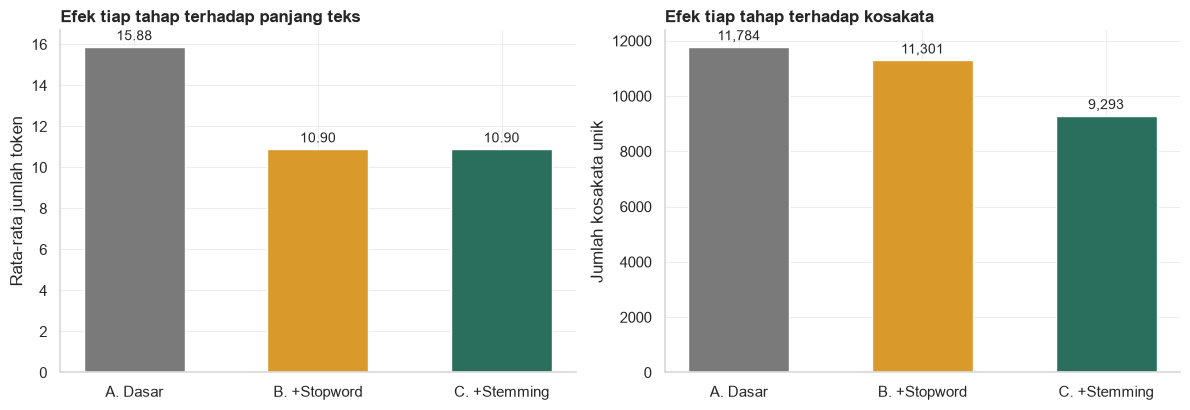

In [9]:
mulai = time.time()
df["tokens_mentah"] = df["review"].apply(
    lambda teks: re.sub(r"[^a-z\s]", " ", str(teks).lower()).split()
)
df["tokens_dasar"] = df["review"].apply(praproses_dasar)
df["tokens_tanpa_stopword"] = df["tokens_dasar"].apply(hapus_stopword)
df["tokens_stem"] = df["tokens_tanpa_stopword"].apply(stemming)
waktu_proses = time.time() - mulai


def metrik_konfigurasi(tokens_series):
    panjang = tokens_series.apply(len)
    kosakata = set()
    for tokens in tokens_series:
        kosakata.update(tokens)
    return {
        "Rata-rata token": panjang.mean(),
        "Median token": panjang.median(),
        "Total token": panjang.sum(),
        "Kosakata unik": len(kosakata),
        "Ulasan kosong": int((panjang == 0).sum()),
        "Ulasan <=2 token": int((panjang <= 2).sum()),
    }


konfigurasi = {
    "A. Dasar": df["tokens_dasar"],
    "B. +Stopword": df["tokens_tanpa_stopword"],
    "C. +Stemming": df["tokens_stem"],
}
tabel_config = pd.DataFrame(
    {nama: metrik_konfigurasi(series) for nama, series in konfigurasi.items()}
).T
tabel_config.index.name = "Konfigurasi"
tabel_config = tabel_config.round(2)
display(tabel_config)

print(f"Waktu proses: {waktu_proses:.2f} detik")
print(f"Kata unik yang di-stem: {len(cache_stem):,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
warna_config = [WARNA["netral"], WARNA["aksen"], WARNA["positif"]]

for i, (nama, nilai) in enumerate(tabel_config["Rata-rata token"].items()):
    ax[0].bar(i, nilai, color=warna_config[i], width=0.55)
    ax[0].text(i, nilai + tabel_config["Rata-rata token"].max() * 0.02, f"{nilai:.2f}", ha="center")
ax[0].set_xticks(range(len(tabel_config)))
ax[0].set_xticklabels(tabel_config.index)
ax[0].set_ylabel("Rata-rata jumlah token")
ax[0].set_title("Efek tiap tahap terhadap panjang teks", loc="left", fontweight="bold")

for i, (nama, nilai) in enumerate(tabel_config["Kosakata unik"].items()):
    ax[1].bar(i, nilai, color=warna_config[i], width=0.55)
    ax[1].text(i, nilai + tabel_config["Kosakata unik"].max() * 0.02, f"{int(nilai):,}", ha="center")
ax[1].set_xticks(range(len(tabel_config)))
ax[1].set_xticklabels(tabel_config.index)
ax[1].set_ylabel("Jumlah kosakata unik")
ax[1].set_title("Efek tiap tahap terhadap kosakata", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

### 3.1 Analisis Leksikal: Sebelum vs Sesudah

Saya bandingkan kata yang paling sering muncul sebelum dan sesudah preprocessing. Sebelum preprocessing, kata fungsi seperti *yang*, *dan*, dan *di* diperkirakan mendominasi. Setelah preprocessing, daftar seharusnya lebih didominasi kata bermakna.

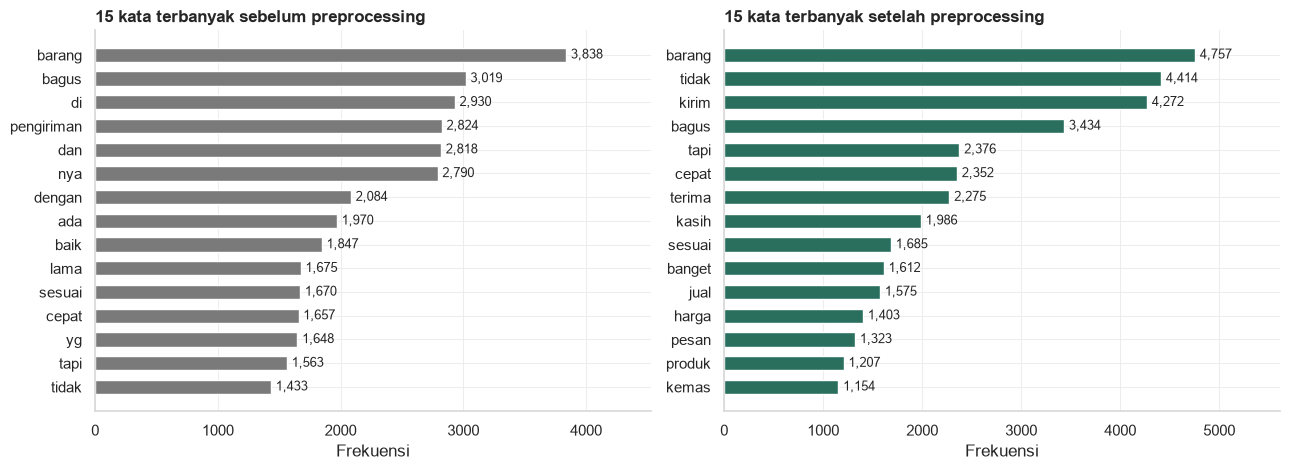

In [10]:
def frekuensi_kata(tokens_series, n=15):
    counter = Counter()
    for tokens in tokens_series:
        counter.update(tokens)
    return counter.most_common(n)


atas_mentah = frekuensi_kata(df["tokens_mentah"], 15)
atas_akhir = frekuensi_kata(df["tokens_stem"], 15)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for axis, data, judul, warna in [
    (ax[0], atas_mentah, "15 kata terbanyak sebelum preprocessing", WARNA["netral"]),
    (ax[1], atas_akhir, "15 kata terbanyak setelah preprocessing", WARNA["positif"]),
]:
    kata = [k for k, _ in data][::-1]
    nilai = [v for _, v in data][::-1]
    axis.barh(kata, nilai, color=warna, height=0.6)
    for y, v in enumerate(nilai):
        axis.text(v + max(nilai) * 0.01, y, f"{v:,}", va="center", fontsize=9)
    axis.set_title(judul, loc="left", fontweight="bold")
    axis.set_xlabel("Frekuensi")
    axis.set_xlim(0, max(nilai) * 1.18)

plt.tight_layout()
plt.show()

### 3.2 Bigram per Sentimen

Bigram membantu melihat frasa yang sering muncul, bukan hanya kata tunggal. Saya memakai token hasil stopword removal tanpa stemming agar bentuk frasa masih mudah dibaca.

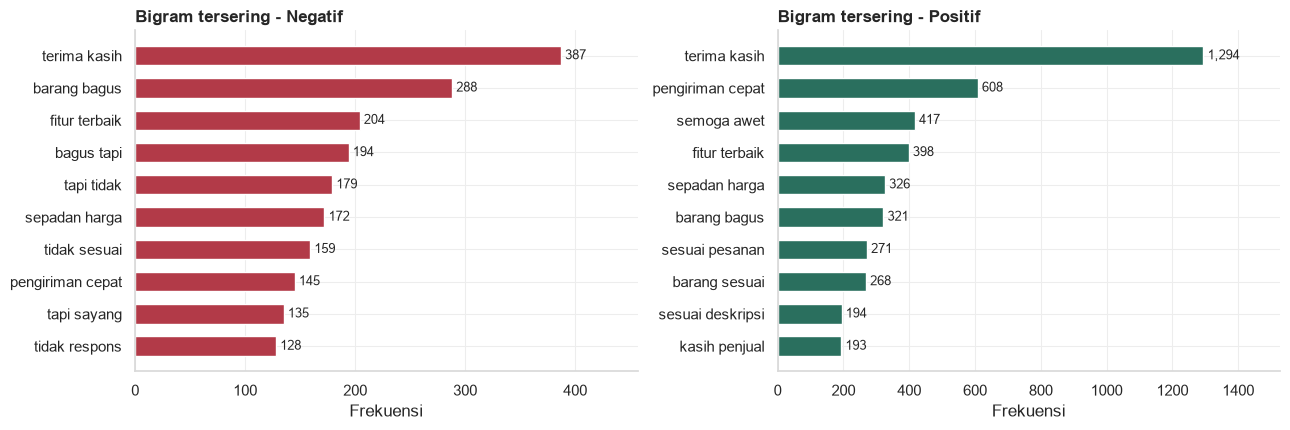

In [11]:
def bigram_teratas(tokens_series, n=10):
    counter = Counter()
    for tokens in tokens_series:
        counter.update(zip(tokens, tokens[1:]))
    return counter.most_common(n)


fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for axis, label in zip(ax, URUTAN_LABEL):
    subset = df.loc[df["sentimen_label"] == label, "tokens_tanpa_stopword"]
    data = bigram_teratas(subset, 10)
    frasa = [f"{a} {b}" for (a, b), _ in data][::-1]
    nilai = [v for _, v in data][::-1]
    axis.barh(frasa, nilai, color=PALET[label], height=0.6)
    for y, v in enumerate(nilai):
        axis.text(v + max(nilai) * 0.01, y, f"{v:,}", va="center", fontsize=9)
    axis.set_title(f"Bigram tersering - {label}", loc="left", fontweight="bold")
    axis.set_xlabel("Frekuensi")
    axis.set_xlim(0, max(nilai) * 1.18)

plt.tight_layout()
plt.show()

### 3.3 Perubahan Bentuk Kata akibat Stemming

Stemming seharusnya menyatukan kata turunan ke bentuk dasar. Tabel berikut menampilkan pasangan kata yang berubah paling sering, sehingga kita bisa menilai apakah perubahannya masuk akal atau terlalu agresif.

In [12]:
pasangan_stem = Counter()
for tokens in df["tokens_tanpa_stopword"]:
    for kata in tokens:
        dasar = stem_kata(kata)
        if dasar != kata:
            pasangan_stem[(kata, dasar)] += 1

tabel_stem = pd.DataFrame(
    [
        {"Sebelum stemming": kata, "Setelah stemming": dasar, "Frekuensi": jumlah}
        for (kata, dasar), jumlah in pasangan_stem.most_common(12)
    ]
)
display(tabel_stem)
print(f"Jumlah pasangan bentuk yang berubah: {len(pasangan_stem):,}")

,Sebelum stemming,Setelah stemming,Frekuensi
0,pengiriman,kirim,2827
1,penjual,jual,1312
2,kemasan,kemas,992
3,semoga,moga,959
4,berfungsi,fungsi,908
5,barangnya,barang,895
6,pesanan,pesan,676
7,terbaik,baik,666
8,sepadan,padan,565
9,pengirimannya,kirim,448


Jumlah pasangan bentuk yang berubah: 2,514


## 4. Audit Kualitas Hasil Preprocessing

Preprocessing yang agresif bisa membuat ulasan pendek atau bahkan kosong. Saya menghitung jumlah ulasan kosong, ulasan dengan dua token atau kurang, dan duplikat setelah pembersihan. Saya juga memeriksa apakah dampaknya berbeda antar sentimen.

In [13]:
df["clean_review"] = df["tokens_stem"].apply(" ".join)
df["jumlah_kata_akhir"] = df["tokens_stem"].apply(len)
df["jumlah_karakter_akhir"] = df["clean_review"].str.len()

kosong = int((df["jumlah_kata_akhir"] == 0).sum())
satu_dua = int(df["jumlah_kata_akhir"].between(1, 2).sum())
pendek_total = int((df["jumlah_kata_akhir"] <= 2).sum())
duplikat_bersih = int(
    df.loc[df["clean_review"].str.strip() != "", "clean_review"].duplicated().sum()
)

kualitas = pd.DataFrame({
    "Metrik": [
        "Ulasan kosong setelah preprocessing",
        "Ulasan dengan 1-2 token",
        "Ulasan dengan <=2 token",
        "Duplikat teks bersih (non-kosong)",
    ],
    "Jumlah": [kosong, satu_dua, pendek_total, duplikat_bersih],
})
kualitas["Persentase (%)"] = (kualitas["Jumlah"] / len(df) * 100).round(2)
display(kualitas)

per_sentimen = (
    df.groupby("sentimen_label")
      .agg(
          Jumlah=("review", "size"),
          Kosong=("jumlah_kata_akhir", lambda s: int((s == 0).sum())),
          Pendek=("jumlah_kata_akhir", lambda s: int((s <= 2).sum())),
      )
      .reindex(URUTAN_LABEL)
)
per_sentimen["Kosong (%)"] = (per_sentimen["Kosong"] / per_sentimen["Jumlah"] * 100).round(2)
per_sentimen["Pendek (%)"] = (per_sentimen["Pendek"] / per_sentimen["Jumlah"] * 100).round(2)
display(per_sentimen)

print("Contoh ulasan terpendek setelah preprocessing:")
display(
    df.nsmallest(5, "jumlah_kata_akhir")[
        ["sentimen_label", "review", "clean_review", "jumlah_kata_akhir"]
    ].reset_index(drop=True)
)

,Metrik,Jumlah,Persentase (%)
0,Ulasan kosong setelah preprocessing,20,0.17
1,Ulasan dengan 1-2 token,739,6.37
2,Ulasan dengan <=2 token,759,6.54
3,Duplikat teks bersih (non-kosong),250,2.15


,Jumlah,Kosong,Pendek,Kosong (%),Pendek (%)
sentimen_label,,,,,
Negatif,5803,9,342,0.16,5.89
Positif,5803,11,417,0.19,7.19


Contoh ulasan terpendek setelah preprocessing:


,sentimen_label,review,clean_review,jumlah_kata_akhir
0,Negatif,#BUKANMAEN,,0
1,Positif,m,,0
2,Negatif,lama,,0
3,Negatif,Lama sampai nya🤧,,0
4,Positif,",,,,,,👍",,0


## 5. Contoh Sebelum dan Sesudah Preprocessing

Saya memilih 5 ulasan negatif dan 5 ulasan positif secara stratifikasi berdasarkan panjang awal. Contoh diambil dari ulasan yang memiliki minimal 8 kata dan hasil preprocessing minimal 3 token, supaya perbandingan tetap informatif. Untuk setiap sentimen, contoh diambil pada posisi 0%, 25%, 50%, 75%, dan 100% setelah data diurutkan menurut jumlah kata. Ulasan yang menjadi kosong atau terlalu pendek dibahas terpisah pada bagian audit kualitas.

In [14]:
def pilih_stratified(frame, label, n=5):
    subset = (
        frame.loc[
            (frame["sentimen_label"] == label)
            & (frame["jumlah_kata_awal"] >= 8)
            & (frame["clean_review"].str.strip() != "")
            & (frame["jumlah_kata_akhir"] >= 3)
        ]
        .sort_values("jumlah_kata_awal")
        .reset_index(drop=True)
    )
    posisi = np.linspace(0, len(subset) - 1, n).astype(int)
    return subset.iloc[posisi]


contoh_df = pd.concat(
    [pilih_stratified(df, "Negatif"), pilih_stratified(df, "Positif")],
    ignore_index=True,
)

tabel_contoh = pd.DataFrame({
    "No": np.arange(1, len(contoh_df) + 1),
    "Sentimen": contoh_df["sentimen_label"],
    "Kata Awal": contoh_df["jumlah_kata_awal"],
    "Sebelum Preprocessing": contoh_df["review"],
    "Sesudah Preprocessing": contoh_df["clean_review"],
    "Kata Akhir": contoh_df["jumlah_kata_akhir"],
})

display(tabel_contoh.set_index("No"))

,Sentimen,Kata Awal,Sebelum Preprocessing,Sesudah Preprocessing,Kata Akhir
No,,,,,
1,Negatif,8,Baguss bgt barangnya\nPengiriman nya ajh yg kurang,bagus banget barang kirim kurang,5
2,Negatif,12,"Ukuran:kek nya barang udah lama, di buka ada yang pecahhh tutupnya",ukur kek barang buka pecah tutup,6
3,Negatif,18,"Fitur Terbaik:retur bos\n\nMaaf kak barang nya rusak saya minta kebijakan nya kak, retur bos\nTerima kasih🙏",fitur baik retur bos maaf kak barang rusak bijak kak retur bos terima kasih,14
4,Negatif,28,Cap Produk oleh penjual tertanda bulan 10 tahun 2019... Padahal belinya 27 Mei 2020... 1 semester lebih... Produk be...,cap produk jual tanda tahun beli mei semester produk fungsi material tidak logitech tapi harga murah rebut beli,18
5,Negatif,234,"Buat saya, POLYTRON adalah sebuah brand besar yang dikenal cukup lama sebagai produsen elektronik lokal di Indonesia...",polytron brand kenal cukup produsen elektronik lokal indonesia namun sangat sayang pribadi alam sangat kurang kemari...,126
6,Positif,8,kualitas produk baik\nProduk original\nHarga produk baik,kualitas produk produk original harga produk,6
7,Positif,10,"Barang sudah sampai dan diterima dalam keadaan baik, packing aman",barang terima kemas aman,4
8,Positif,14,"Pengiriman cepat, chatt ramah harga murah. Blm dites krn unt dijual lg. Makasih seller",kirim cepat chat ramah harga murah belum tes jual terima kasih jual,12
9,Positif,20,"Kok pada komen pengiriman lama deh, ini gua aja cuma 3 hari sampe 😑 pesen jumat, selasa sampe (sabtu minggu gak diit...",komentar kirim deh pesan jumat selasa sabtu minggu tidak diitung,10


## 6. Dampak Preprocessing terhadap Ukuran dan Kosakata

Bagian ini membandingkan kondisi sebelum dan sesudah preprocessing pada seluruh dataset. Saya memakai token mentah hasil case folding dan pembersihan tanda baca sebagai pembanding, lalu menghitung perubahan panjang karakter, jumlah kata, dan ukuran kosakata.

In [15]:
def gabung_kosakata(tokens_series):
    kosakata = set()
    for tokens in tokens_series:
        kosakata.update(tokens)
    return kosakata


vocab_mentah = gabung_kosakata(df["tokens_mentah"])
vocab_akhir = gabung_kosakata(df["tokens_stem"])

rata_karakter_awal = df["review"].str.len().mean()
rata_karakter_akhir = df["clean_review"].str.len().mean()
median_karakter_awal = df["review"].str.len().median()
median_karakter_akhir = df["clean_review"].str.len().median()

rata_kata_awal = df["tokens_mentah"].apply(len).mean()
rata_kata_akhir = df["jumlah_kata_akhir"].mean()
median_kata_awal = df["tokens_mentah"].apply(len).median()
median_kata_akhir = df["jumlah_kata_akhir"].median()
max_kata_awal = int(df["tokens_mentah"].apply(len).max())
max_kata_akhir = int(df["jumlah_kata_akhir"].max())
total_token_awal = int(df["tokens_mentah"].apply(len).sum())
total_token_akhir = int(df["jumlah_kata_akhir"].sum())

indikator = [
    ("Rata-rata panjang karakter", rata_karakter_awal, rata_karakter_akhir, 2),
    ("Median panjang karakter", median_karakter_awal, median_karakter_akhir, 0),
    ("Rata-rata jumlah kata", rata_kata_awal, rata_kata_akhir, 2),
    ("Median jumlah kata", median_kata_awal, median_kata_akhir, 0),
    ("Kata terbanyak", max_kata_awal, max_kata_akhir, 0),
    ("Total token", total_token_awal, total_token_akhir, 0),
    ("Kosakata unik", len(vocab_mentah), len(vocab_akhir), 0),
]

tabel_dampak = pd.DataFrame([
    {
        "Indikator": nama,
        "Sebelum": f"{sebelum:,.{desimal}f}",
        "Sesudah": f"{sesudah:,.{desimal}f}",
        "Perubahan (%)": f"{(1 - sesudah / sebelum) * 100:.1f}" if sebelum else "0.0",
    }
    for nama, sebelum, sesudah, desimal in indikator
])
display(tabel_dampak)

print(f"Rasio kompresi token : {total_token_akhir / total_token_awal:.3f}")
print(f"Rasio kompresi kosakata: {len(vocab_akhir) / len(vocab_mentah):.3f}")

,Indikator,Sebelum,Sesudah,Perubahan (%)
0,Rata-rata panjang karakter,103.57,67.71,34.6
1,Median panjang karakter,78,53,32.1
2,Rata-rata jumlah kata,15.74,10.90,30.7
3,Median jumlah kata,12,8,33.3
4,Kata terbanyak,234,126,46.2
5,Total token,"182,713","126,547",30.7
6,Kosakata unik,"12,558","9,293",26.0


Rasio kompresi token : 0.693
Rasio kompresi kosakata: 0.740


### 6.1 Distribusi Token dan Pertumbuhan Kosakata

Boxplot/violin memperlihatkan perubahan sebaran panjang ulasan. Kurva kosakata kumulatif memperlihatkan seberapa cepat kosakata bertambah ketika ulasan diproses satu per satu; kurva yang lebih landai berarti kosakata lebih terkonsentrasi.

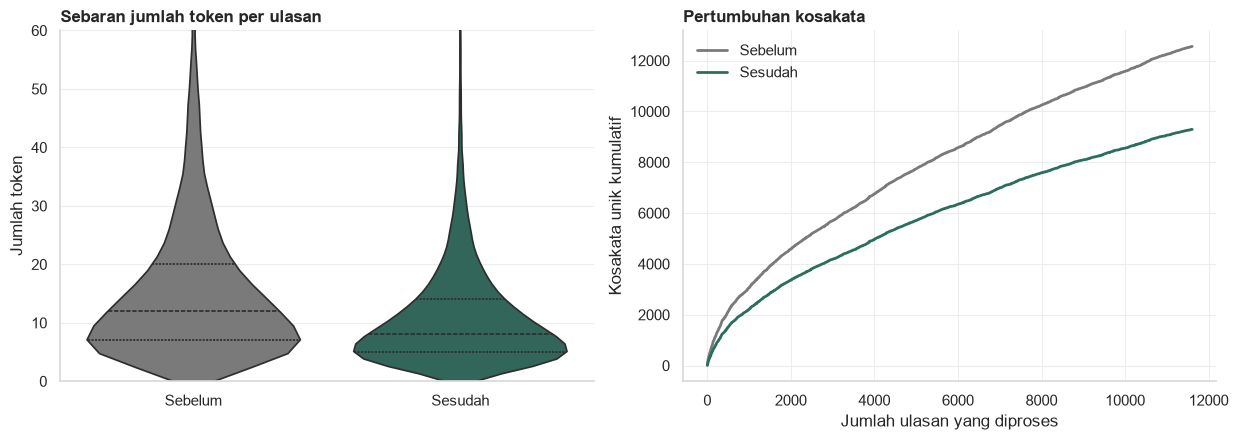

In [16]:
def kurva_kosakata(tokens_series):
    terlihat = set()
    hasil = []
    for tokens in tokens_series:
        terlihat.update(tokens)
        hasil.append(len(terlihat))
    return hasil


data_plot = pd.DataFrame({
    "Tahap": ["Sebelum"] * len(df) + ["Sesudah"] * len(df),
    "Jumlah token": pd.concat(
        [df["tokens_mentah"].apply(len), df["jumlah_kata_akhir"]],
        ignore_index=True,
    ),
})

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))

sns.violinplot(
    data=data_plot,
    x="Tahap",
    y="Jumlah token",
    hue="Tahap",
    order=["Sebelum", "Sesudah"],
    hue_order=["Sebelum", "Sesudah"],
    palette=[WARNA["netral"], WARNA["positif"]],
    inner="quartile",
    cut=0,
    legend=False,
    ax=ax[0],
)
ax[0].set_ylim(0, 60)
ax[0].set_xlabel("")
ax[0].set_ylabel("Jumlah token")
ax[0].set_title("Sebaran jumlah token per ulasan", loc="left", fontweight="bold")

kurva_mentah = kurva_kosakata(df["tokens_mentah"])
kurva_akhir = kurva_kosakata(df["tokens_stem"])
ax[1].plot(range(1, len(df) + 1), kurva_mentah, label="Sebelum", color=WARNA["netral"], linewidth=2)
ax[1].plot(range(1, len(df) + 1), kurva_akhir, label="Sesudah", color=WARNA["positif"], linewidth=2)
ax[1].set_xlabel("Jumlah ulasan yang diproses")
ax[1].set_ylabel("Kosakata unik kumulatif")
ax[1].set_title("Pertumbuhan kosakata", loc="left", fontweight="bold")
ax[1].legend(frameon=False)

plt.tight_layout()
plt.show()

## 7. Apakah Negasi Masih Terjaga?

Kata negasi adalah salah satu informasi paling penting untuk analisis sentimen. Saya menghitung jumlah ulasan yang mengandung negasi sebelum dan sesudah preprocessing, lalu menampilkan beberapa contoh hasil akhirnya.

Jumlah ulasan yang terdeteksi mengandung negasi bisa **naik** setelah preprocessing. Penyebabnya bukan penambahan kata baru, melainkan normalisasi: bentuk seperti *gabisa*, *gada*, dan *gpp* baru terurai menjadi *tidak bisa*, *tidak ada*, dan *tidak apa-apa*. Dengan kata lain, tahap ini justru membuat negasi implisit menjadi eksplisit.

In [17]:
def mengandung_negasi(tokens):
    return any(kata in NEGASI for kata in tokens)


negasi_awal = int(df["tokens_mentah"].apply(mengandung_negasi).sum())
negasi_akhir = int(df["tokens_stem"].apply(mengandung_negasi).sum())

tabel_negasi = pd.DataFrame({
    "Tahap": ["Sebelum preprocessing", "Sesudah preprocessing"],
    "Ulasan mengandung negasi": [negasi_awal, negasi_akhir],
    "Persentase (%)": [
        round(negasi_awal / len(df) * 100, 2),
        round(negasi_akhir / len(df) * 100, 2),
    ],
})
display(tabel_negasi)

contoh_negasi = df.loc[
    df["tokens_stem"].apply(mengandung_negasi),
    ["sentimen_label", "review", "clean_review"],
].head(5)
print("Contoh ulasan yang masih memuat negasi setelah preprocessing:")
display(contoh_negasi.reset_index(drop=True))

,Tahap,Ulasan mengandung negasi,Persentase (%)
0,Sebelum preprocessing,4020,34.64
1,Sesudah preprocessing,4242,36.55


Contoh ulasan yang masih memuat negasi setelah preprocessing:


,sentimen_label,review,clean_review
0,Negatif,Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala,suara mic puas pesan nyala pasti klik nyala tapi tidak nyala
1,Negatif,Kualitas produk baik. Harga terjangkau dan pengirimannya cepet banget. Udh 3x order disini oke lah tp sayangnya klo ...,kualitas produk harga jangkau kirim cepat banget pesan oke tapi sayang kado tidak nitip pakai kartu ucap bungkus pak...
2,Negatif,"Overall bagus, tombol berfungsi semuanya, tapi packaging kurang karena sudah penyot dan robek sedikit",overall bagus tombol fungsi tapi kemas kurang penyot robek
3,Negatif,pesanan di terima tanggal 27 January 2021 tetapi baru bisa saya buka pagi ini tanggal 29 January 2021 pukul 06.00 da...,pesan terima tanggal january tetapi buka pagi tanggal january tab sketsa advan tidak nyala sekali cas posisi tab tid...
4,Negatif,Perlu ditingkatkan packagingnya..masak iya pake clear wrap aja..paling nggak kan dimasukin ke kantong plastik dulu l...,tingkat kemas masak iya pakai clear wrap paling tidak dimasukin kantong plastik wrap so far tidak keluh produk harga...


### 7.1 Ringkasan Angka Kunci

Sel ringkasan ini merangkum angka utama secara otomatis dari variabel yang sudah dihitung, sehingga angka di narasi selalu konsisten dengan hasil eksekusi.

In [18]:
display(Markdown(f"""
**Ringkasan angka kunci**

| Indikator | Sebelum | Sesudah | Perubahan |
|---|---:|---:|---:|
| Rata-rata jumlah kata | {rata_kata_awal:.2f} | {rata_kata_akhir:.2f} | -{(1 - rata_kata_akhir / rata_kata_awal) * 100:.1f}% |
| Median jumlah kata | {median_kata_awal:.0f} | {median_kata_akhir:.0f} | -{(1 - median_kata_akhir / median_kata_awal) * 100:.1f}% |
| Rata-rata panjang karakter | {rata_karakter_awal:.2f} | {rata_karakter_akhir:.2f} | -{(1 - rata_karakter_akhir / rata_karakter_awal) * 100:.1f}% |
| Total token | {total_token_awal:,} | {total_token_akhir:,} | -{(1 - total_token_akhir / total_token_awal) * 100:.1f}% |
| Kosakata unik | {len(vocab_mentah):,} | {len(vocab_akhir):,} | -{(1 - len(vocab_akhir) / len(vocab_mentah)) * 100:.1f}% |
| Ulasan mengandung negasi | {negasi_awal:,} | {negasi_akhir:,} | {(negasi_akhir / negasi_awal - 1) * 100:+.1f}% |

- Ulasan kosong setelah preprocessing: **{kosong:,}** ({kosong / len(df) * 100:.2f}%)
- Ulasan dengan <=2 token: **{pendek_total:,}** ({pendek_total / len(df) * 100:.2f}%)
- Konfigurasi A (dasar): rata-rata **{tabel_config.loc['A. Dasar', 'Rata-rata token']:.2f}** token, kosakata **{int(tabel_config.loc['A. Dasar', 'Kosakata unik']):,}**
- Konfigurasi B (+stopword): rata-rata **{tabel_config.loc['B. +Stopword', 'Rata-rata token']:.2f}** token, kosakata **{int(tabel_config.loc['B. +Stopword', 'Kosakata unik']):,}**
- Konfigurasi C (+stemming): rata-rata **{tabel_config.loc['C. +Stemming', 'Rata-rata token']:.2f}** token, kosakata **{int(tabel_config.loc['C. +Stemming', 'Kosakata unik']):,}**
"""))


**Ringkasan angka kunci**

| Indikator | Sebelum | Sesudah | Perubahan |
|---|---:|---:|---:|
| Rata-rata jumlah kata | 15.74 | 10.90 | -30.7% |
| Median jumlah kata | 12 | 8 | -33.3% |
| Rata-rata panjang karakter | 103.57 | 67.71 | -34.6% |
| Total token | 182,713 | 126,547 | -30.7% |
| Kosakata unik | 12,558 | 9,293 | -26.0% |
| Ulasan mengandung negasi | 4,020 | 4,242 | +5.5% |

- Ulasan kosong setelah preprocessing: **20** (0.17%)
- Ulasan dengan <=2 token: **759** (6.54%)
- Konfigurasi A (dasar): rata-rata **15.88** token, kosakata **11,784**
- Konfigurasi B (+stopword): rata-rata **10.90** token, kosakata **11,301**
- Konfigurasi C (+stemming): rata-rata **10.90** token, kosakata **9,293**


## 8. Diskusi

Hasil perbandingan konfigurasi menunjukkan bahwa setiap tahap punya peran yang berbeda. Cleaning dan normalisasi menghilangkan noise serta menyeragamkan singkatan, stopword removal memangkas kata fungsi yang mendominasi frekuensi, sedangkan stemming menurunkan variasi bentuk kata. Penurunan jumlah token paling besar terjadi ketika stopword removal ditambahkan, sementara stemming tidak mengubah jumlah token sama sekali; pengaruhnya terlihat pada penurunan kosakata. Ini masuk akal karena stemming hanya mengganti bentuk kata, bukan menghapus token.

Normalisasi slang memberi perbaikan yang tidak terlihat pada metrik ukuran saja. Kata seperti *gak*, *ga*, dan *tdk* disatukan menjadi *tidak*, sehingga negasi lebih mudah dikenali. Pengulangan huruf seperti *bagusss* juga dinormalkan sebelum stemming. Tanpa tahap ini, variasi ejaan akan dianggap sebagai kata berbeda dan menambah dimensi fitur.

Stemming memang menurunkan kosakata, tetapi tidak selalu tepat. Sastrawi kadang memotong kata terlalu jauh, misalnya *perhatikan* menjadi *perhati*. Stemmer Sastrawi sendiri juga tidak mengenali kata Inggris seperti *packing*; pipeline ini menambalnya lewat kamus, tetapi kata Inggris lain yang belum terdaftar masih bisa lolos. Karena itu, stemming perlu dipakai dengan hati-hati jika hasilnya akan dipakai untuk pemodelan: penurunan kosakata yang besar belum tentu diikuti peningkatan kualitas semantik.

Dari sisi kualitas data, sebagian ulasan menjadi kosong atau tersisa sangat sedikit token. Ulasan seperti ini kehilangan konteks dan berisiko diberi label yang tidak lagi didukung teks. Selain itu, setelah pembersihan muncul ratusan teks yang identik meskipun sebelumnya berbeda. Duplikat baru ini perlu ditangani sebelum pemodelan agar evaluasi tidak bias. Distribusi label tetap seimbang karena preprocessing tidak menghapus baris, tetapi kualitas per baris tidak seragam. Temuan ini perlu dilaporkan sebagai keterbatasan, bukan disembunyikan.

## 9. Keterbatasan dan Rekomendasi

**Keterbatasan**

1. Kamus slang hanya mencakup bentuk yang saya temukan di dataset ini; singkatan lain atau salah ketik baru masih bisa lolos.
2. Emoji dihapus, padahal emoji kadang membawa sinyal sentimen yang kuat.
3. Stemming Sastrawi dapat memotong kata terlalu agresif. Stemmer ini juga tidak menangani kata Inggris; sebagian sudah ditambal kamus, tetapi kata lain yang belum terdaftar masih bisa lolos.
4. Sebagian ulasan menjadi kosong atau sangat pendek setelah preprocessing.
5. Dataset masih mengandung ulasan duplikat dan kemungkinan label noise.
6. Notebook ini berhenti pada preprocessing; belum ada evaluasi model klasifikasi.

**Rekomendasi**

1. Tambahkan kamus normalisasi yang lebih lengkap dan validasi manual pada sampel.
2. Pertimbangkan pemetaan emoji ke penanda sentimen sebelum emoji dihapus.
3. Bandingkan pipeline dengan dan tanpa stemming saat melatih model, bukan menganggap stemming selalu lebih baik.
4. Tangani ulasan kosong atau <=2 token secara eksplisit, misalnya dengan menghapus, menggabungkan, atau memberi kategori khusus.
5. Hapus atau tandai duplikat sebelum pemodelan agar evaluasi tidak bias.
6. Lanjutkan ke tahap TF-IDF dan model baseline seperti Naive Bayes atau regresi logistik untuk mengukur apakah preprocessing ini benar-benar membantu.

## 10. Kesimpulan

Pipeline preprocessing berhasil dijalankan pada seluruh dataset tanpa mengubah file sumber. Lima tahap utama diterapkan secara modular, dengan tambahan normalisasi slang dan pengulangan huruf. Kata negasi, intensifier, dan konjungsi kontras dipertahankan agar polaritas kalimat tidak hilang.

Perbandingan tiga konfigurasi memperlihatkan bahwa stopword removal dan stemming memberikan kontribusi terbesar terhadap penurunan jumlah token dan kosakata. Namun, penurunan ukuran teks juga membawa risiko: sejumlah ulasan menjadi kosong atau terlalu pendek untuk dianalisis. Hasil ini lebih jujur dipakai sebagai dasar pemodelan berikutnya, dengan catatan bahwa pemilihan tahap preprocessing sebaiknya diuji secara empiris, bukan hanya dipilih karena menghasilkan teks paling pendek.

In [19]:
metrik_json = {
    "jumlah_ulasan": int(len(df)),
    "negatif": int((df["sentimen"] == 0).sum()),
    "positif": int((df["sentimen"] == 1).sum()),
    "duplikat_review": duplikat_review,
    "stopword_sastrawi": len(STOPWORD_SASTRAWI),
    "kata_penting": len(KATA_PENTING),
    "stopword_dipakai": len(STOPWORD),
    "kamus_slang": len(KAMUS_SLANG),
    "rata_karakter_awal": float(rata_karakter_awal),
    "rata_karakter_akhir": float(rata_karakter_akhir),
    "median_karakter_awal": float(median_karakter_awal),
    "median_karakter_akhir": float(median_karakter_akhir),
    "rata_kata_awal": float(rata_kata_awal),
    "rata_kata_akhir": float(rata_kata_akhir),
    "median_kata_awal": float(median_kata_awal),
    "median_kata_akhir": float(median_kata_akhir),
    "max_kata_awal": max_kata_awal,
    "max_kata_akhir": max_kata_akhir,
    "total_token_awal": total_token_awal,
    "total_token_akhir": total_token_akhir,
    "vocab_mentah": len(vocab_mentah),
    "vocab_akhir": len(vocab_akhir),
    "kosong": kosong,
    "satu_dua_token": satu_dua,
    "pendek_total": pendek_total,
    "duplikat_bersih": duplikat_bersih,
    "negasi_awal": negasi_awal,
    "negasi_akhir": negasi_akhir,
    "waktu_proses": round(float(waktu_proses), 2),
    "konfigurasi": {
        nama: {k: float(v) for k, v in baris.items()}
        for nama, baris in tabel_config.iterrows()
    },
}

print("METRIK_JSON")
print(json.dumps(metrik_json, ensure_ascii=False, indent=2))

METRIK_JSON
{
  "jumlah_ulasan": 11606,
  "negatif": 5803,
  "positif": 5803,
  "duplikat_review": 7,
  "stopword_sastrawi": 809,
  "kata_penting": 30,
  "stopword_dipakai": 787,
  "kamus_slang": 121,
  "rata_karakter_awal": 103.57203170773738,
  "rata_karakter_akhir": 67.70877132517663,
  "median_karakter_awal": 78.0,
  "median_karakter_akhir": 53.0,
  "rata_kata_awal": 15.742977770118904,
  "rata_kata_akhir": 10.903584352920904,
  "median_kata_awal": 12.0,
  "median_kata_akhir": 8.0,
  "max_kata_awal": 234,
  "max_kata_akhir": 126,
  "total_token_awal": 182713,
  "total_token_akhir": 126547,
  "vocab_mentah": 12558,
  "vocab_akhir": 9293,
  "kosong": 20,
  "satu_dua_token": 739,
  "pendek_total": 759,
  "duplikat_bersih": 250,
  "negasi_awal": 4020,
  "negasi_akhir": 4242,
  "waktu_proses": 2.8,
  "konfigurasi": {
    "A. Dasar": {
      "Rata-rata token": 15.88,
      "Median token": 12.0,
      "Total token": 184273.0,
      "Kosakata unik": 11784.0,
      "Ulasan kosong": 4.0,
   